In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

(530, 2)


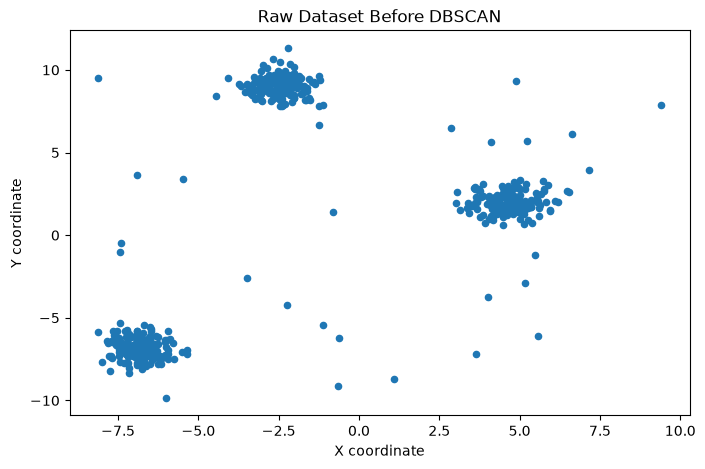

In [3]:
# Generate three groups of data points
X, _ = make_blobs(
    n_samples=500,
    centers=3,
    cluster_std=0.6,
    random_state=42
)

# Add some random noise points
rng = np.random.default_rng(42)

noise = rng.uniform(
    low=-10,
    high=10,
    size=(30, 2)
)

X = np.vstack([X, noise])

# Put the coordinates into a DataFrame
df = pd.DataFrame(X, columns=["x", "y"])

print(df.shape)
df.head()

plt.figure(figsize=(8, 5))

plt.scatter(df["x"], df["y"], s=20)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Raw Dataset Before DBSCAN")
plt.show()

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#train the model

dbscan = DBSCAN(
    eps = 0.3,
    min_samples=5
)

labels = dbscan.fit_predict(X_scaled)

df['cluster'] = labels
df

,x,y,cluster
0,-6.190063,-7.302015,0
1,3.021747,1.940593,1
2,5.953761,1.488191,1
3,-2.744463,8.136177,2
4,5.360607,1.728324,1
...,...,...,...
525,-6.001836,-9.852755,-1
526,5.738488,3.297017,1
527,4.103308,5.614581,-1
528,-0.821684,1.374824,-1


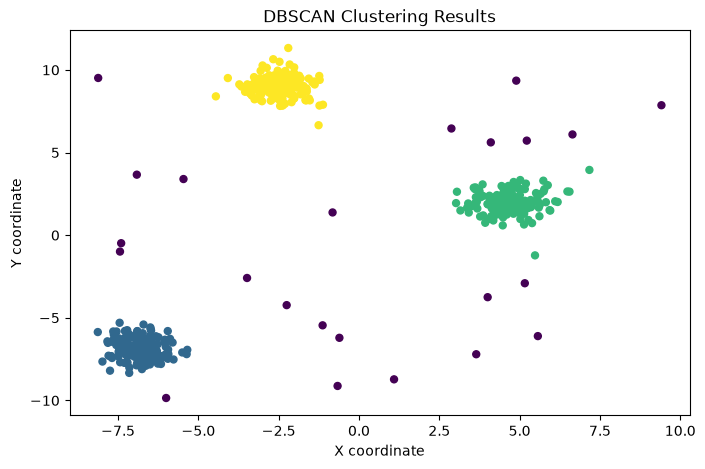

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["x"],
    df["y"],
    c=df["cluster"],
    cmap="viridis",
    s=25
)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("DBSCAN Clustering Results")
plt.show()

In [8]:
# Get points that are not noise
clustered_data = df[df["cluster"] != -1]

# Calculate silhouette score
score = silhouette_score(
    clustered_data[["x", "y"]],
    clustered_data["cluster"]
)

print("Silhouette score:", round(score, 3))

Silhouette score: 0.903


In [9]:
import joblib
from pathlib import Path

# Create models directory
Path("../models").mkdir(exist_ok=True)

# Save the DBSCAN model
joblib.dump(
    dbscan,
    "../models/dbscan_v1.joblib"
)

# Save the scaler too
joblib.dump(
    scaler,
    "../models/dbscan_scaler_v1.joblib"
)

print("Model and scaler saved successfully.")

Model and scaler saved successfully.
